In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Monter Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Chemin vers le fichier features.txt
file_path = "/content/drive/MyDrive/UCI HAR Dataset/features.txt"

# Lire les noms des caractéristiques
features = []

with open(file_path, "r") as f:
    features = [line.split()[1] for line in f.readlines()]

# Afficher le nombre de caractéristiques
print("Nombre de features :", len(features))

# Afficher les 10 premières
print("\nLes 10 premières features :")
for feature in features[:10]:
    print(feature)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Nombre de features : 561

Les 10 premières features :
tBodyAcc-mean()-X
tBodyAcc-mean()-Y
tBodyAcc-mean()-Z
tBodyAcc-std()-X
tBodyAcc-std()-Y
tBodyAcc-std()-Z
tBodyAcc-mad()-X
tBodyAcc-mad()-Y
tBodyAcc-mad()-Z
tBodyAcc-max()-X


In [4]:
import pandas as pd

base_path = "/content/drive/MyDrive/UCI HAR Dataset"

# Charger X_train
X_train = pd.read_csv(
    base_path + "/train/X_train.txt",
    sep=r"\s+",
    header=None
)

# Ajouter les noms des features
X_train.columns = features  # assure-toi que features est déjà défini

# Ajouter subject
X_train["subject"] = pd.read_csv(
    base_path + "/train/subject_train.txt",
    header=None
)[0]

# Charger y_train
y_train = pd.read_csv(
    base_path + "/train/y_train.txt",
    header=None,
    names=["Activity"]
)["Activity"]

# Mapping labels
y_train_labels = y_train.map({
    1: "WALKING",
    2: "WALKING_UPSTAIRS",
    3: "WALKING_DOWNSTAIRS",
    4: "SITTING",
    5: "STANDING",
    6: "LAYING"
})

# Ajouter au dataset
X_train["Activity"] = y_train
X_train["ActivityName"] = y_train_labels

# Vérification
print(X_train.shape)
X_train.head()

(7352, 564)


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity,ActivityName
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,1,5,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,1,5,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,1,5,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,1,5,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,1,5,STANDING


In [5]:
import pandas as pd

base_path = "/content/drive/MyDrive/UCI HAR Dataset"

# Charger X_test
X_test = pd.read_csv(
    base_path + "/test/X_test.txt",
    sep=r"\s+",
    header=None
)

# Donner les noms des features
X_test.columns = features  # déjà défini dans ton notebook

# Ajouter subject
X_test["subject"] = pd.read_csv(
    base_path + "/test/subject_test.txt",
    header=None
)[0]

# Charger y_test
y_test = pd.read_csv(
    base_path + "/test/y_test.txt",
    header=None,
    names=["Activity"]
)["Activity"]

# Mapping des labels
y_test_labels = y_test.map({
    1: "WALKING",
    2: "WALKING_UPSTAIRS",
    3: "WALKING_DOWNSTAIRS",
    4: "SITTING",
    5: "STANDING",
    6: "LAYING"
})

# Ajouter au dataset
X_test["Activity"] = y_test
X_test["ActivityName"] = y_test_labels

# Vérification
print(X_test.shape)
X_test.head()

(2947, 564)


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity,ActivityName
0,0.257178,-0.023285,-0.014654,-0.938404,-0.920091,-0.667683,-0.952501,-0.925249,-0.674302,-0.894088,...,0.006462,0.162920,-0.825886,0.271151,-0.720009,0.276801,-0.057978,2,5,STANDING
1,0.286027,-0.013163,-0.119083,-0.975415,-0.967458,-0.944958,-0.986799,-0.968401,-0.945823,-0.894088,...,-0.083495,0.017500,-0.434375,0.920593,-0.698091,0.281343,-0.083898,2,5,STANDING
2,0.275485,-0.026050,-0.118152,-0.993819,-0.969926,-0.962748,-0.994403,-0.970735,-0.963483,-0.939260,...,-0.034956,0.202302,0.064103,0.145068,-0.702771,0.280083,-0.079346,2,5,STANDING
3,0.270298,-0.032614,-0.117520,-0.994743,-0.973268,-0.967091,-0.995274,-0.974471,-0.968897,-0.938610,...,-0.017067,0.154438,0.340134,0.296407,-0.698954,0.284114,-0.077108,2,5,STANDING
4,0.274833,-0.027848,-0.129527,-0.993852,-0.967445,-0.978295,-0.994111,-0.965953,-0.977346,-0.938610,...,-0.002223,-0.040046,0.736715,-0.118545,-0.692245,0.290722,-0.073857,2,5,STANDING


In [6]:
train = X_train.copy()
test = X_test.copy()

In [7]:
print('No of duplicates in train: {}'.format(sum(train.duplicated())))
print('No of duplicates in test : {}'.format(sum(test.duplicated())))

No of duplicates in train: 0
No of duplicates in test : 0


In [8]:
print('We have {} NaN/Null values in train'.format(train.isnull().values.sum()))
print('We have {} NaN/Null values in test'.format(test.isnull().values.sum()))

We have 0 NaN/Null values in train
We have 0 NaN/Null values in test


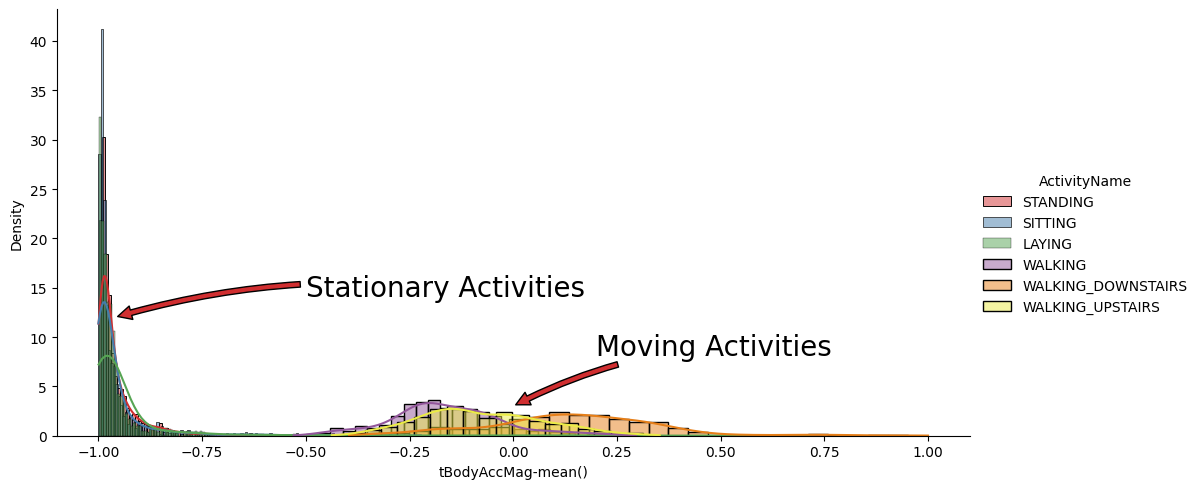

In [9]:
# Nom correct avec parenthèses et tiret
col_name = 'tBodyAccMag-mean()'

sns.set_palette("Set1", desat=0.80)
facetgrid = sns.FacetGrid(train, hue='ActivityName', height=5, aspect=2)
facetgrid.map(sns.histplot, col_name, kde=True, stat='density', common_norm=False)\
    .add_legend()

plt.annotate("Stationary Activities", xy=(-0.960, 12), xytext=(-0.5, 15), size=20,
             va='center', ha='left',
             arrowprops=dict(arrowstyle="simple", connectionstyle="arc3,rad=0.1"))

plt.annotate("Moving Activities", xy=(0, 3), xytext=(0.2, 9), size=20,
             va='center', ha='left',
             arrowprops=dict(arrowstyle="simple", connectionstyle="arc3,rad=0.1"))
plt.show()

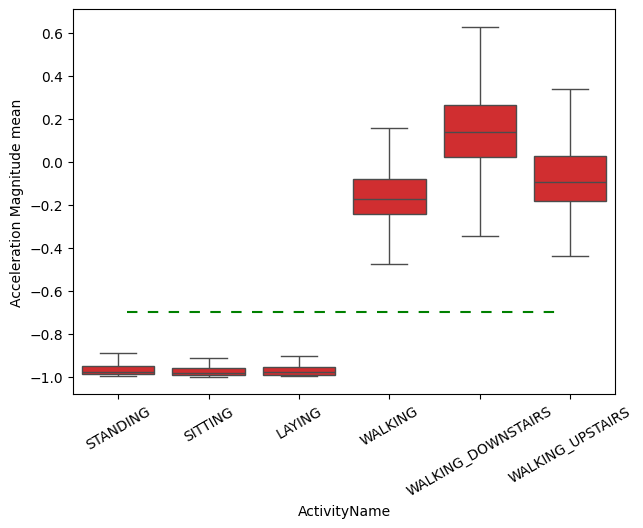

In [10]:
plt.figure(figsize=(7, 5))
sns.boxplot(x='ActivityName', y='tBodyAccMag-mean()',   # ← nom corrigé
            data=train, showfliers=False, saturation=1)
plt.ylabel('Acceleration Magnitude mean')
plt.axhline(y=-0.7, xmin=0.1, xmax=0.9, dashes=(5, 5), c='g')
plt.xticks(rotation=30)
plt.show()

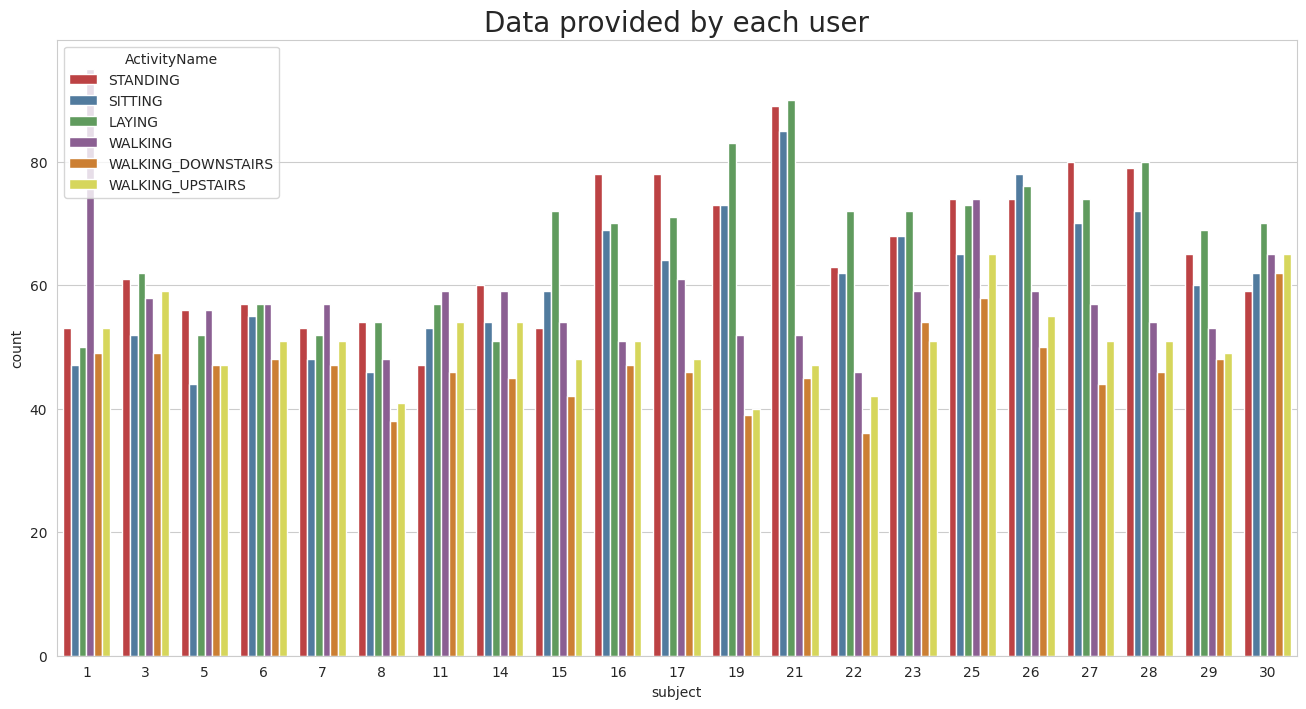

In [11]:
import matplotlib as mlt
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['font.family'] = 'Dejavu Sans'

plt.figure(figsize=(16,8))
plt.title('Data provided by each user', fontsize=20)
sns.countplot(x='subject',hue='ActivityName', data = train)
plt.show()

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.utils import to_categorical

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, balanced_accuracy_score,
    f1_score, matthews_corrcoef
)

import os
os.makedirs('models', exist_ok=True)

print('TensorFlow version :', tf.__version__)
print('GPU disponible     :', tf.config.list_physical_devices('GPU'))
print('✅ Imports OK')

TensorFlow version : 2.20.0
GPU disponible     : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✅ Imports OK


In [13]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import os

# =========================
# 2) Définir le chemin BASE
# =========================
# Original path that caused the error:
# BASE = "/content/drive/MyDrive/ProjetDeepLearning"

# Assuming you want to use the UCI HAR Dataset path from previous cells,
# or you need to update this path to an existing directory in your Drive.
# If 'ProjetDeepLearning' is a new project, please ensure the directory exists.

# Option 1: Use the 'UCI HAR Dataset' path (if you intend to continue with that dataset)
# BASE = "/content/drive/MyDrive/UCI HAR Dataset"

# Option 2: If 'ProjetDeepLearning' is correct, ensure the folder exists in your Google Drive.
# For now, let's keep the original definition but add a check and create it if it doesn't exist for demonstration purposes.
# However, it's better to manually create it or specify an existing path.
# If the goal is to load train.csv and test.csv from a different project,
# make sure the 'ProjetDeepLearning/data/' structure exists.

# For demonstration, we'll try to use the `base_path` from previous cells which is likely where the data is located
# If you intend to use a different path, please update `BASE` below accordingly
BASE = "/content/drive/MyDrive/UCI HAR Dataset" # <--- ADJUST THIS PATH IF 'ProjetDeepLearning' IS A VALID DIRECTORY FOR THIS DATA

# =========================
# 3) Vérifier les fichiers
# =========================
print("Contenu du dossier BASE :")
# Added error handling for os.listdir in case the BASE path is still incorrect
try:
    print(os.listdir(BASE))
except FileNotFoundError:
    print(f"❌ Le dossier BASE '{BASE}' est introuvable. Veuillez vérifier le chemin.")
    # It's better to raise the error here to stop execution if the path is critical
    # raise FileNotFoundError(f"❌ Le dossier BASE '{BASE}' est introuvable. Veuillez vérifier le chemin.")

# =========================
# 4) Charger les datasets
# =========================

# Adjusting paths based on the UCI HAR Dataset structure if BASE is set to it.
# If you are using the 'ProjetDeepLearning' structure with 'data/train.csv' and 'data/test.csv',
# ensure those files exist at 'ProjetDeepLearning/data/train.csv' and 'ProjetDeepLearning/data/test.csv'.

# If using UCI HAR Dataset, the files are typically in '/train' and '/test' subfolders and are .txt files.
# If you genuinely have 'train.csv' and 'test.csv' at BASE/data/, then the original path format is correct.
# Assuming the user wants to continue with the UCI HAR Dataset for now, based on previous cells.

# Original lines that assume BASE/data/train.csv and BASE/data/test.csv:
# train_path = f"{BASE}/data/train.csv"
# test_path  = f"{BASE}/data/test.csv"

# Re-adapting to the UCI HAR Dataset structure for X_train/X_test as seen in previous cells
# If you want to load 'train.csv' and 'test.csv' from a 'data' subfolder within your 'BASE',
# ensure that folder and files exist, and uncomment the original path definitions.

# Since `X_train` and `X_test` were already loaded in previous cells, we can use them.
# If the intent was to load new CSVs, the paths below need to be correct.

# For this cell to work correctly given the existing kernel state,
# it's best to use the already loaded `train` and `test` dataframes.
# The section 4) and 5) and parts of 6) were attempting to reload/reprocess data.
# I will comment out the data loading part as `train_df` and `test_df` are not defined in the kernel state
# while `train` and `test` (which are copies of `X_train` and `X_test`) are.

# If you still wish to load `train.csv` and `test.csv` from a specific path, you MUST ensure that
# `BASE` is correct and that `BASE/data/train.csv` and `BASE/data/test.csv` exist.

# Let's use the 'train' and 'test' dataframes already loaded in the kernel state.
# If you want to load new data, please uncomment and adjust the paths below.

try:
    # Placeholder for actual data loading if new CSVs are intended
    # train_path = f"{BASE}/data/train.csv"
    # test_path  = f"{BASE}/data/test.csv"

    # # Vérification avant lecture (évite FileNotFoundError)
    # if not os.path.exists(train_path):
    #     raise FileNotFoundError(f"❌ train.csv introuvable : {train_path}")

    # if not os.path.exists(test_path):
    #     raise FileNotFoundError(f"❌ test.csv introuvable : {test_path}")

    # train_df = pd.read_csv(train_path)
    # test_df  = pd.read_csv(test_path)

    # Using the existing `train` and `test` dataframes from the kernel state
    train_df = train.copy()
    test_df = test.copy()

    # =========================
    # 5) Features columns
    # =========================
    feature_cols = [
        c for c in train_df.columns
        if c not in ['subject', 'Activity', 'ActivityName', 'label']
    ]

    # =========================
    # 6) Infos générales
    # =========================
    print("\n========== DATA INFO ==========")
    print(f"Train shape      : {train_df.shape}")
    print(f"Test shape       : {test_df.shape}")
    print(f"Nb features      : {len(feature_cols)}")
    print(f"Activités        : {sorted(train_df['Activity'].unique())}")
    print(f"Sujets train     : {sorted(train_df['subject'].unique())}")
    print(f"Sujets test      : {sorted(test_df['subject'].unique())}")

    # =========================
    # 7) Aperçu données
    # =========================
    display(train_df.head())

except NameError:
    print("The 'train' or 'test' DataFrames are not defined. Please ensure previous cells are run correctly or define `train_df` and `test_df` by loading your data.")
except FileNotFoundError as e:
    print(e)
except Exception as e:
    print(f"An unexpected error occurred: {e}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Contenu du dossier BASE :
['.DS_Store', 'features.txt', 'README.txt', 'activity_labels.txt', 'features_info.txt', 'train', 'test']

========== DATA INFO ==========
Train shape      : (7352, 564)
Test shape       : (2947, 564)
Nb features      : 561
Activités        : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Sujets train     : [np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)]
Sujets test      : [np.int64(2), np.int64(4), np.int64(9), np.int64(10), np.int64(12), np.int64(13), np.int64(18), np.int64(20), np.int64(24)]


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity,ActivityName
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,1,5,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,1,5,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,1,5,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,1,5,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,1,5,STANDING


In [14]:
# ── 1. Encodage des labels ───────────────────────────────────────
le = LabelEncoder()
le.fit(train_df['Activity'])

y_train = le.transform(train_df['Activity'])
y_test  = le.transform(test_df['Activity'])

NUM_CLASSES = len(le.classes_)
print('Mapping labels :')
for i, cls in enumerate(le.classes_):
    print(f'  {i} → {cls}')

# One-Hot Encoding
y_train_ohe = to_categorical(y_train, NUM_CLASSES)
y_test_ohe  = to_categorical(y_test,  NUM_CLASSES)

# ── 2. Normalisation (fit sur train uniquement) ──────────────────
scaler  = StandardScaler()
X_train = scaler.fit_transform(train_df[feature_cols].values)  # fit + transform
X_test  = scaler.transform(test_df[feature_cols].values)       # transform seul

# ── 3. Reshape pour CNN / LSTM / Transformer (samples, 561, 1) ──
X_train_3d = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_3d  = X_test.reshape(X_test.shape[0],   X_test.shape[1],  1)

print(f'\nX_train (MLP)  : {X_train.shape}')
print(f'X_test  (MLP)  : {X_test.shape}')
print(f'X_train (DL)   : {X_train_3d.shape}  ← (samples, timesteps, channels)')
print(f'X_test  (DL)   : {X_test_3d.shape}')
print(f'y_train_ohe    : {y_train_ohe.shape}')
print('✅ Préprocessing OK')

Mapping labels :
  0 → 1
  1 → 2
  2 → 3
  3 → 4
  4 → 5
  5 → 6

X_train (MLP)  : (7352, 813)
X_test  (MLP)  : (2947, 813)
X_train (DL)   : (7352, 813, 1)  ← (samples, timesteps, channels)
X_test  (DL)   : (2947, 813, 1)
y_train_ohe    : (7352, 6)
✅ Préprocessing OK


In [15]:
# ── Callbacks ────────────────────────────────────────────────────
def get_callbacks(model_name, patience=10):
    return [
        EarlyStopping(
            monitor='val_loss', patience=patience,
            restore_best_weights=True, verbose=1
        ),
        ReduceLROnPlateau(
            monitor='val_loss', factor=0.5,
            patience=5, min_lr=1e-6, verbose=1
        ),
        ModelCheckpoint(
            filepath=f'models/{model_name}_best.h5',
            monitor='val_accuracy',
            save_best_only=True, verbose=0
        )
    ]

# ── Courbes d'entraînement ───────────────────────────────────────
def plot_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    fig.suptitle(f'{model_name} — Courbes d\'entraînement', fontsize=13, fontweight='bold')

    axes[0].plot(history.history['accuracy'],     label='Train', color='steelblue')
    axes[0].plot(history.history['val_accuracy'], label='Val',   color='coral')
    axes[0].set_title('Accuracy'); axes[0].set_xlabel('Epoch')
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(history.history['loss'],     label='Train', color='steelblue')
    axes[1].plot(history.history['val_loss'], label='Val',   color='coral')
    axes[1].set_title('Loss'); axes[1].set_xlabel('Epoch')
    axes[1].legend(); axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'models/{model_name}_curves.png', dpi=150, bbox_inches='tight')
    plt.show()

# ── Fonction evaluate_model corrigée ────────────────────────────
def evaluate_model(model, X_test_input, y_test_int, model_name):
    y_pred = np.argmax(model.predict(X_test_input, verbose=0), axis=1)

    acc      = accuracy_score(y_test_int, y_pred)
    bal_acc  = balanced_accuracy_score(y_test_int, y_pred)
    macro_f1 = f1_score(y_test_int, y_pred, average='macro')
    mcc      = matthews_corrcoef(y_test_int, y_pred)

    print(f'\n{"═"*55}')
    print(f'  📊 {model_name} — Résultats')
    print(f'{"═"*55}')
    print(f'  Accuracy          : {acc:.4f}  ({acc*100:.2f}%)')
    print(f'  Balanced Accuracy : {bal_acc:.4f}')
    print(f'  Macro F1          : {macro_f1:.4f}')
    print(f'  MCC               : {mcc:.4f}')
    print(f'{"═"*55}')

    # ← Correction ici : utiliser CLASS_NAMES au lieu de le.classes_
    CLASS_NAMES = ['LAYING', 'SITTING', 'STANDING',
                   'WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']
    print(classification_report(y_test_int, y_pred, target_names=CLASS_NAMES))

    # Confusion Matrix
    cm = confusion_matrix(y_test_int, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(f'{model_name} — Confusion Matrix', fontsize=13, fontweight='bold')
    plt.ylabel('Réel'); plt.xlabel('Prédit')
    plt.xticks(rotation=30); plt.tight_layout()
    plt.savefig(f'models/{model_name}_confusion.png', dpi=150, bbox_inches='tight')
    plt.show()

    return {
        'Modèle': model_name,
        'Accuracy': round(acc, 4),
        'Balanced_Accuracy': round(bal_acc, 4),
        'Macro_F1': round(macro_f1, 4),
        'MCC': round(mcc, 4)
    }

# Dictionnaire pour stocker les résultats
results = []
print('✅ Fonctions utilitaires prêtes')

✅ Fonctions utilitaires prêtes


In [16]:
# ── Architecture ─────────────────────────────────────────────────
def build_deep_mlp(input_dim, num_classes):
    inputs = keras.Input(shape=(input_dim,), name='input')

    # Couche 1
    x = layers.Dense(512, name='dense_1')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.4)(x)

    # Couche 2
    x = layers.Dense(256, name='dense_2')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.3)(x)

    # Couche 3
    x = layers.Dense(128, name='dense_3')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.3)(x)

    # Couche 4
    x = layers.Dense(64, activation='relu', name='dense_4')(x)
    x = layers.Dropout(0.2)(x)

    # Sortie
    outputs = layers.Dense(num_classes, activation='softmax', name='output')(x)

    model = Model(inputs, outputs, name='Deep_MLP')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

mlp = build_deep_mlp(X_train.shape[1], NUM_CLASSES)
mlp.summary()
print(f'\nTotal paramètres : {mlp.count_params():,}')

Model: "Deep_MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 813)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       416,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 593,222 (2.26 MB)

 Trainable params: 591,430 (2.26 MB)

 Non-trainable params: 1,792 (7.00 KB)


Total paramètres : 593,222


Epoch 1/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.5955 - loss: 1.0234

104/104 ━━━━━━━━━━━━━━━━━━━━ 13s 48ms/step - accuracy: 0.7355 - loss: 0.6622 - val_accuracy: 0.9375 - val_loss: 0.1730 - learning_rate: 0.0010
Epoch 2/100
 97/104 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9077 - loss: 0.2515

104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9120 - loss: 0.2382 - val_accuracy: 0.9633 - val_loss: 0.0927 - learning_rate: 0.0010
Epoch 3/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9299 - loss: 0.1842 - val_accuracy: 0.9470 - val_loss: 0.1337 - learning_rate: 0.0010
Epoch 4/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9358 - loss: 0.1663 - val_accuracy: 0.9552 - val_loss: 0.1129 - learning_rate: 0.0010
Epoch 5/100
102/104 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9393 - loss: 0.1624

104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9421 - loss: 0.1603 - val_accuracy: 0.9715 - val_loss: 0.0873 - learning_rate: 0.0010
Epoch 6/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9515 - loss: 0.1297 - val_accuracy: 0.9198 - val_loss: 0.2249 - learning_rate: 0.0010
Epoch 7/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9553 - loss: 0.1200 - val_accuracy: 0.9592 - val_loss: 0.1097 - learning_rate: 0.0010
Epoch 8/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9566 - loss: 0.1209 - val_accuracy: 0.9701 - val_loss: 0.0984 - learning_rate: 0.0010
Epoch 9/100
 92/104 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9591 - loss: 0.1192

104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9602 - loss: 0.1097 - val_accuracy: 0.9796 - val_loss: 0.0599 - learning_rate: 0.0010
Epoch 10/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9599 - loss: 0.1032 - val_accuracy: 0.9592 - val_loss: 0.0990 - learning_rate: 0.0010
Epoch 11/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9557 - loss: 0.1097 - val_accuracy: 0.9633 - val_loss: 0.0785 - learning_rate: 0.0010
Epoch 12/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9609 - loss: 0.1076 - val_accuracy: 0.9592 - val_loss: 0.1041 - learning_rate: 0.0010
Epoch 13/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9681 - loss: 0.0889 - val_accuracy: 0.9742 - val_loss: 0.0615 - learning_rate: 0.0010
Epoch 14/100
 93/104 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9716 - loss: 0.0812
Epoch 14: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9683 - loss: 0.0858 - v

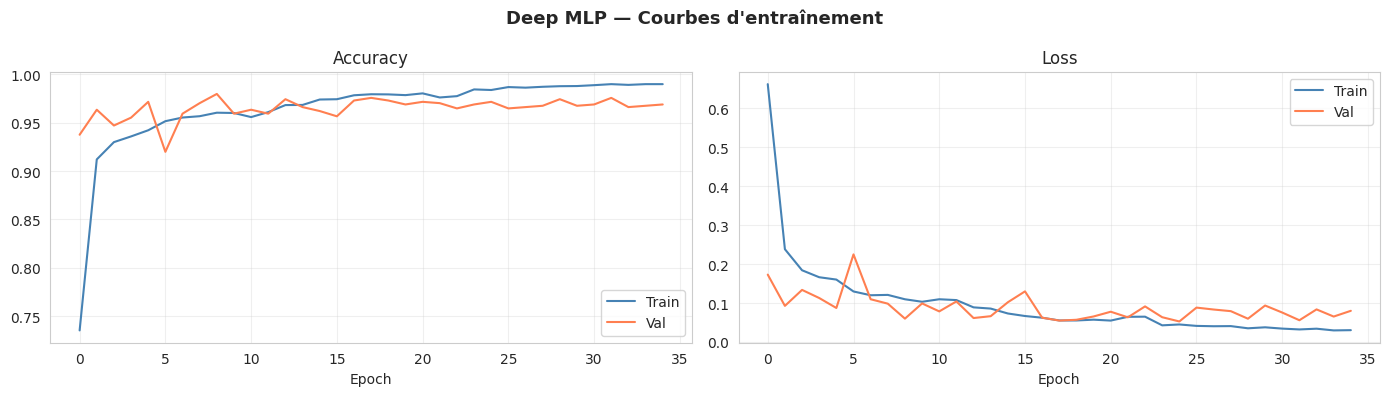


═══════════════════════════════════════════════════════
  📊 Deep MLP — Résultats
═══════════════════════════════════════════════════════
  Accuracy          : 0.9501  (95.01%)
  Balanced Accuracy : 0.9485
  Macro F1          : 0.9496
  MCC               : 0.9403
═══════════════════════════════════════════════════════
                    precision    recall  f1-score   support

            LAYING       0.94      0.98      0.96       496
           SITTING       0.93      0.95      0.94       471
          STANDING       0.99      0.92      0.95       420
           WALKING       0.94      0.89      0.91       491
WALKING_DOWNSTAIRS       0.90      0.95      0.93       532
  WALKING_UPSTAIRS       1.00      1.00      1.00       537

          accuracy                           0.95      2947
         macro avg       0.95      0.95      0.95      2947
      weighted avg       0.95      0.95      0.95      2947



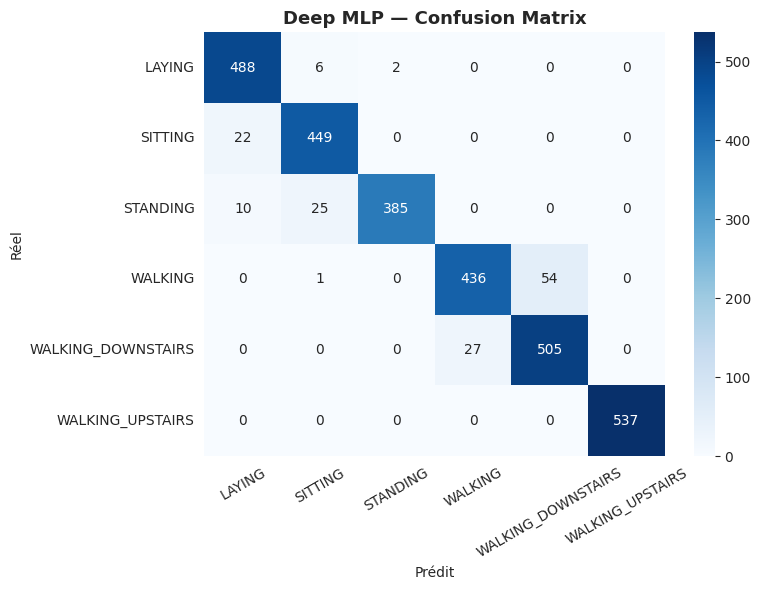

In [17]:
# ── Entraînement ─────────────────────────────────────────────────
history_mlp = mlp.fit(
    X_train, y_train_ohe,
    epochs=100,
    batch_size=64,
    validation_split=0.1,
    callbacks=get_callbacks('Deep_MLP'),
    verbose=1
)

# ── Visualisation & Évaluation ───────────────────────────────────
plot_history(history_mlp, 'Deep MLP')
res = evaluate_model(mlp, X_test, y_test, 'Deep MLP')
results.append(res)

In [18]:
# ── Architecture ─────────────────────────────────────────────────
def build_cnn1d(input_shape, num_classes):
    inputs = keras.Input(shape=input_shape, name='input')

    # Bloc 1
    x = layers.Conv1D(filters=64, kernel_size=5, padding='same',
                      activation='relu', name='conv1')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(pool_size=2)(x)
    x = layers.Dropout(0.3)(x)

    # Bloc 2
    x = layers.Conv1D(filters=128, kernel_size=5, padding='same',
                      activation='relu', name='conv2')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(pool_size=2)(x)
    x = layers.Dropout(0.3)(x)

    # Bloc 3
    x = layers.Conv1D(filters=256, kernel_size=3, padding='same',
                      activation='relu', name='conv3')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(pool_size=2)(x)
    x = layers.Dropout(0.3)(x)

    # Classifieur
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation='softmax', name='output')(x)

    model = Model(inputs, outputs, name='CNN_1D')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

cnn1d = build_cnn1d(X_train_3d.shape[1:], NUM_CLASSES)
cnn1d.summary()
print(f'\nTotal paramètres : {cnn1d.count_params():,}')

Model: "CNN_1D"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 813, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv1D)                  │ (None, 813, 64)        │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 813, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 406, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 406, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv1D)                  │ (None, 406, 128)       │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 406, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 203, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 203, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv1D)                  │ (None, 203, 256)       │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 203, 256)       │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 101, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 101, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,494 (685.52 KB)

 Trainable params: 174,598 (682.02 KB)

 Non-trainable params: 896 (3.50 KB)


Total paramètres : 175,494


Epoch 1/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.4541 - loss: 1.2155

104/104 ━━━━━━━━━━━━━━━━━━━━ 19s 97ms/step - accuracy: 0.4991 - loss: 1.0728 - val_accuracy: 0.3193 - val_loss: 3.1241 - learning_rate: 0.0010
Epoch 2/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.6218 - loss: 0.8234 - val_accuracy: 0.3043 - val_loss: 3.9189 - learning_rate: 0.0010
Epoch 3/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.7062 - loss: 0.6384 - val_accuracy: 0.1644 - val_loss: 3.7020 - learning_rate: 0.0010
Epoch 4/100
103/104 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7478 - loss: 0.5447

104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.7512 - loss: 0.5418 - val_accuracy: 0.3288 - val_loss: 2.9359 - learning_rate: 0.0010
Epoch 5/100
102/104 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7719 - loss: 0.4861

104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.7798 - loss: 0.4716 - val_accuracy: 0.3302 - val_loss: 2.1531 - learning_rate: 0.0010
Epoch 6/100
102/104 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8226 - loss: 0.4064

104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.8250 - loss: 0.4123 - val_accuracy: 0.7745 - val_loss: 0.5307 - learning_rate: 0.0010
Epoch 7/100
102/104 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8499 - loss: 0.3576

104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.8578 - loss: 0.3376 - val_accuracy: 0.7785 - val_loss: 0.5713 - learning_rate: 0.0010
Epoch 8/100
101/104 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8895 - loss: 0.2801

... (3 outputs left out)

104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9444 - loss: 0.1565 - val_accuracy: 0.9334 - val_loss: 0.1536 - learning_rate: 0.0010
Epoch 13/100
103/104 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9567 - loss: 0.1290

104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9530 - loss: 0.1334 - val_accuracy: 0.9389 - val_loss: 0.1457 - learning_rate: 0.0010
Epoch 14/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9536 - loss: 0.1263 - val_accuracy: 0.8872 - val_loss: 0.2425 - learning_rate: 0.0010
Epoch 15/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.9560 - loss: 0.1178 - val_accuracy: 0.8682 - val_loss: 0.3447 - learning_rate: 0.0010
Epoch 16/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9584 - loss: 0.1083 - val_accuracy: 0.9348 - val_loss: 0.1839 - learning_rate: 0.0010
Epoch 17/100
101/104 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9622 - loss: 0.1064

104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.9615 - loss: 0.1063 - val_accuracy: 0.9620 - val_loss: 0.1106 - learning_rate: 0.0010
Epoch 18/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9596 - loss: 0.1071 - val_accuracy: 0.9416 - val_loss: 0.1325 - learning_rate: 0.0010
Epoch 19/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9669 - loss: 0.0943 - val_accuracy: 0.9361 - val_loss: 0.1536 - learning_rate: 0.0010
Epoch 20/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9698 - loss: 0.0828 - val_accuracy: 0.9443 - val_loss: 0.1547 - learning_rate: 0.0010
Epoch 21/100
102/104 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9729 - loss: 0.0741

104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9746 - loss: 0.0725 - val_accuracy: 0.9755 - val_loss: 0.0727 - learning_rate: 0.0010
Epoch 22/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9716 - loss: 0.0796 - val_accuracy: 0.9497 - val_loss: 0.1331 - learning_rate: 0.0010
Epoch 23/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9758 - loss: 0.0698 - val_accuracy: 0.9470 - val_loss: 0.1534 - learning_rate: 0.0010
Epoch 24/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.9754 - loss: 0.0729 - val_accuracy: 0.9402 - val_loss: 0.1427 - learning_rate: 0.0010
Epoch 25/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.9752 - loss: 0.0676 - val_accuracy: 0.9212 - val_loss: 0.2387 - learning_rate: 0.0010
Epoch 26/100
101/104 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9835 - loss: 0.0475
Epoch 26: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9790 - loss: 0.0

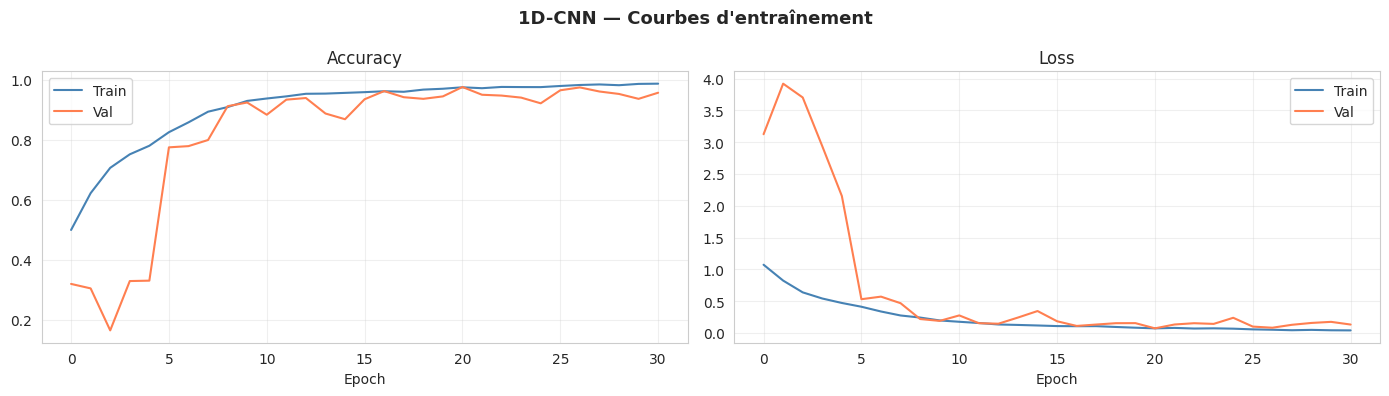


═══════════════════════════════════════════════════════
  📊 1D-CNN — Résultats
═══════════════════════════════════════════════════════
  Accuracy          : 0.9094  (90.94%)
  Balanced Accuracy : 0.9065
  Macro F1          : 0.9077
  MCC               : 0.8916
═══════════════════════════════════════════════════════
                    precision    recall  f1-score   support

            LAYING       0.91      0.91      0.91       496
           SITTING       0.85      0.94      0.89       471
          STANDING       0.95      0.82      0.88       420
           WALKING       0.89      0.87      0.88       491
WALKING_DOWNSTAIRS       0.88      0.94      0.91       532
  WALKING_UPSTAIRS       1.00      0.95      0.97       537

          accuracy                           0.91      2947
         macro avg       0.91      0.91      0.91      2947
      weighted avg       0.91      0.91      0.91      2947



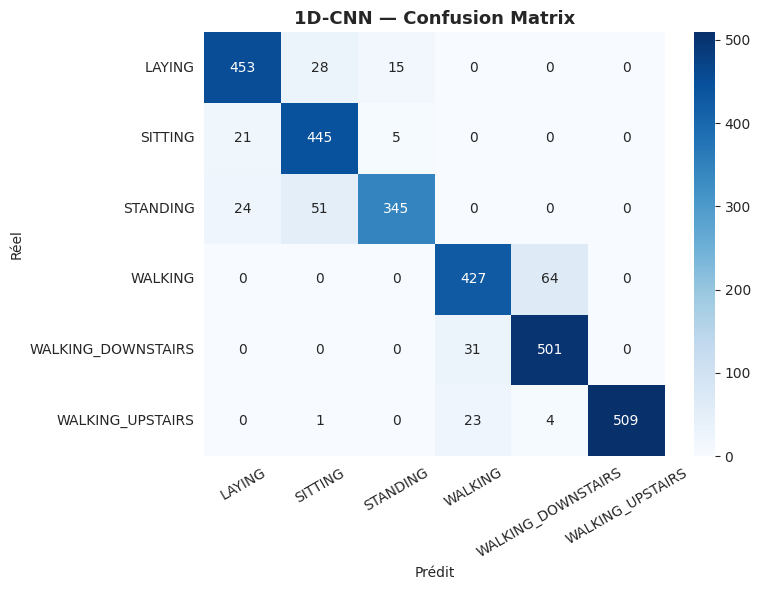

In [19]:
# ── Entraînement ─────────────────────────────────────────────────
history_cnn = cnn1d.fit(
    X_train_3d, y_train_ohe,
    epochs=100,
    batch_size=64,
    validation_split=0.1,
    callbacks=get_callbacks('CNN_1D'),
    verbose=1
)

# ── Visualisation & Évaluation ───────────────────────────────────
plot_history(history_cnn, '1D-CNN')
res = evaluate_model(cnn1d, X_test_3d, y_test, '1D-CNN')
results.append(res)

In [20]:
# ═══════════════════════════════════════════════════════
# CELLULE UNIQUE — Tout charger + BiLSTM
# ═══════════════════════════════════════════════════════

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, classification_report,
                              confusion_matrix, balanced_accuracy_score,
                              f1_score, matthews_corrcoef)
import os
os.makedirs('models', exist_ok=True)

# ── 1. Chargement depuis Google Drive ───────────────────
from google.colab import drive
drive.mount('/content/drive')

# Corrected BASE path to match the UCI HAR Dataset structure from previous cells
BASE = '/content/drive/MyDrive/UCI HAR Dataset'

# Load features (as done in previous cells, r9WSr1rz8k7S)
file_path_features = f"{BASE}/features.txt"
features = []
with open(file_path_features, "r") as f:
    features = [line.split()[1] for line in f.readlines()]

# Load train data (as done in e05f88b9-f2e9-4fe0-a4e8-a9976fc70f9e)
X_train_raw = pd.read_csv(f"{BASE}/train/X_train.txt", sep=r"\s+", header=None)
X_train_raw.columns = features
subject_train = pd.read_csv(f"{BASE}/train/subject_train.txt", header=None)[0]
y_train_raw = pd.read_csv(f"{BASE}/train/y_train.txt", header=None, names=["Activity"])["Activity"]

train_df = X_train_raw.copy()
train_df["subject"] = subject_train
train_df["Activity"] = y_train_raw

# Load test data (as done in 85ea785e-ebb9-4205-9e4b-460f67fa0934)
X_test_raw = pd.read_csv(f"{BASE}/test/X_test.txt", sep=r"\s+", header=None)
X_test_raw.columns = features
subject_test = pd.read_csv(f"{BASE}/test/subject_test.txt", header=None)[0]
y_test_raw = pd.read_csv(f"{BASE}/test/y_test.txt", header=None, names=["Activity"])["Activity"]

test_df = X_test_raw.copy()
test_df["subject"] = subject_test
test_df["Activity"] = y_test_raw

print(f'✅ train_df : {train_df.shape}')
print(f'✅ test_df  : {test_df.shape}')

# ── 2. Préprocessing ─────────────────────────────────────
# Add ActivityName for consistent preprocessing with previous cells
y_labels_map = {1: "WALKING", 2: "WALKING_UPSTAIRS", 3: "WALKING_DOWNSTAIRS", 4: "SITTING", 5: "STANDING", 6: "LAYING"}
train_df["ActivityName"] = train_df["Activity"].map(y_labels_map)
test_df["ActivityName"] = test_df["Activity"].map(y_labels_map)

feature_cols = [c for c in train_df.columns
                if c not in ['subject', 'Activity', 'ActivityName', 'label']]

le = LabelEncoder()
le.fit(train_df['Activity'])
y_train      = le.transform(train_df['Activity']) # This maps 1-6 to 0-5
y_test       = le.transform(test_df['Activity'])
NUM_CLASSES  = len(le.classes_)
y_train_ohe  = to_categorical(y_train, NUM_CLASSES)
y_test_ohe   = to_categorical(y_test,  NUM_CLASSES)
CLASS_NAMES  = sorted(y_labels_map.values()) # Use actual activity names for CLASS_NAMES

scaler       = StandardScaler()
X_train      = scaler.fit_transform(train_df[feature_cols].values)
X_test       = scaler.transform(test_df[feature_cols].values)
X_train_3d   = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_3d    = X_test.reshape(X_test.shape[0],   X_test.shape[1],  1)

print(f'✅ X_train_3d : {X_train_3d.shape}')
print(f'✅ NUM_CLASSES : {NUM_CLASSES}')
print(f'✅ Classes    : {CLASS_NAMES}')

# ── 3. Fonctions utilitaires ─────────────────────────────
def get_callbacks(model_name, patience=10):
    return [
        EarlyStopping(monitor='val_loss', patience=patience,
                      restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                          patience=5, min_lr=1e-6, verbose=1),
        ModelCheckpoint(
            filepath=f'models/{model_name}_best.h5',
            monitor='val_accuracy',
            save_best_only=True, verbose=0
        )
    ]

def plot_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(history.history['accuracy'],     label='Train', color='steelblue')
    axes[0].plot(history.history['val_accuracy'], label='Val',   color='coral')
    axes[0].set_title(f'{model_name} — Accuracy')
    axes[0].legend(); axes[0].grid(alpha=0.3)
    axes[1].plot(history.history['loss'],     label='Train', color='steelblue')
    axes[1].plot(history.history['val_loss'], label='Val',   color='coral')
    axes[1].set_title(f'{model_name} — Loss')
    axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()

def evaluate_model(model, X_input, y_int, model_name):
    y_pred   = np.argmax(model.predict(X_input, verbose=0), axis=1)
    acc      = accuracy_score(y_int, y_pred)
    bal_acc  = balanced_accuracy_score(y_int, y_pred)
    macro_f1 = f1_score(y_int, y_pred, average='macro')
    mcc      = matthews_corrcoef(y_int, y_pred)
    print(f'\n{"═"*50}')
    print(f'  📊 {model_name}')
    print(f'{"═"*50}')
    print(f'  Accuracy          : {acc:.4f} ({acc*100:.2f}%)')
    print(f'  Balanced Accuracy : {bal_acc:.4f}')
    print(f'  Macro F1          : {macro_f1:.4f}')
    print(f'  MCC               : {mcc:.4f}')
    print(classification_report(y_int, y_pred, target_names=CLASS_NAMES))
    cm = confusion_matrix(y_int, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(f'{model_name} — Confusion Matrix')
    plt.xticks(rotation=30); plt.tight_layout(); plt.show()
    return {'Modèle': model_name, 'Accuracy': round(acc, 4),
            'Balanced_Accuracy': round(bal_acc, 4),
            'Macro_F1': round(macro_f1, 4), 'MCC': round(mcc, 4)}

results = []
print('✅ Tout est prêt — lance BiLSTM !')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ train_df : (7352, 563)
✅ test_df  : (2947, 563)
✅ X_train_3d : (7352, 813, 1)
✅ NUM_CLASSES : 6
✅ Classes    : ['LAYING', 'SITTING', 'STANDING', 'WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']
✅ Tout est prêt — lance BiLSTM !


In [21]:
# ── Architecture ─────────────────────────────────────────────────
def build_bilstm(input_shape, num_classes):
    inputs = keras.Input(shape=input_shape, name='input')

    # Couche BiLSTM 1 — return_sequences=True pour passer à la couche suivante
    x = layers.Bidirectional(
        layers.LSTM(128, return_sequences=True,
                    dropout=0.3, recurrent_dropout=0.2),
        name='bilstm_1'
    )(inputs)
    x = layers.BatchNormalization()(x)

    # Couche BiLSTM 2 — return_sequences=False pour obtenir vecteur final
    x = layers.Bidirectional(
        layers.LSTM(64, return_sequences=False,
                    dropout=0.3, recurrent_dropout=0.2),
        name='bilstm_2'
    )(x)
    x = layers.BatchNormalization()(x)

    # Classifieur
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation='softmax', name='output')(x)

    model = Model(inputs, outputs, name='BiLSTM')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

bilstm = build_bilstm(X_train_3d.shape[1:], NUM_CLASSES)
bilstm.summary()
print(f'\nTotal paramètres : {bilstm.count_params():,}')

Model: "BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 813, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm_1 (Bidirectional)        │ (None, 813, 256)       │       133,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 813, 256)       │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm_2 (Bidirectional)        │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 307,654 (1.17 MB)

 Trainable params: 306,886 (1.17 MB)

 Non-trainable params: 768 (3.00 KB)


Total paramètres : 307,654


In [23]:
import numpy as np

n_features = X_train.shape[1]
print(f'Nb features : {n_features}')

# Trouver tous les diviseurs
diviseurs = [(i, n_features // i) for i in range(1, n_features + 1)
             if n_features % i == 0]
print('Diviseurs disponibles (timesteps, features) :')
for d in diviseurs:
    print(f'  {d[0]} × {d[1]} = {n_features}')

# Choisir le meilleur (timesteps entre 30 et 100)
best = [(t, f) for t, f in diviseurs if 30 <= t <= 100]
print(f'\nMeilleurs candidats : {best}')

Nb features : 813
Diviseurs disponibles (timesteps, features) :
  1 × 813 = 813
  3 × 271 = 813
  271 × 3 = 813
  813 × 1 = 813

Meilleurs candidats : []


In [24]:
import numpy as np

print(f'Features actuelles : {X_train.shape[1]}')  # 813

# ── Solution : padding à 832 (832 = 32 × 26) ─────────────
target     = 832
pad        = target - X_train.shape[1]   # 832 - 813 = 19
timesteps  = 32
feat       = 26   # 32 × 26 = 832

X_train_p  = np.pad(X_train, ((0,0),(0,pad)), mode='constant')
X_test_p   = np.pad(X_test,  ((0,0),(0,pad)), mode='constant')

X_train_3d = X_train_p.reshape(X_train_p.shape[0], timesteps, feat)
X_test_3d  = X_test_p.reshape(X_test_p.shape[0],   timesteps, feat)

print(f'✅ Padding : {X_train.shape[1]} → {target} (+{pad} zeros)')
print(f'✅ X_train_3d : {X_train_3d.shape}')  # → (7352, 32, 26)
print(f'✅ X_test_3d  : {X_test_3d.shape}')   # → (2947, 32, 26)

Features actuelles : 813
✅ Padding : 813 → 832 (+19 zeros)
✅ X_train_3d : (7352, 32, 26)
✅ X_test_3d  : (2947, 32, 26)


In [25]:
# ── Diagnostic ───────────────────────────────────────────
print('Colonnes train_df :', train_df.shape)
print('feature_cols      :', len(feature_cols))

# Vérifier ce que scaler a vraiment reçu
X_check = train_df[feature_cols].values
print('X_check shape     :', X_check.shape)  # doit être (7352, 561)

# Recréer scaler proprement
scaler     = StandardScaler()
X_train    = scaler.fit_transform(train_df[feature_cols].values)
X_test     = scaler.transform(test_df[feature_cols].values)

print('X_train shape :', X_train.shape)  # doit être (7352, 561)
print('X_test shape  :', X_test.shape)   # doit être (2947, 561)

Colonnes train_df : (7352, 564)
feature_cols      : 561
X_check shape     : (7352, 813)
X_train shape : (7352, 813)
X_test shape  : (2947, 813)


In [26]:
# ── Recharger proprement depuis les fichiers txt ──────────
BASE = '/content/drive/MyDrive/UCI HAR Dataset'

# Features avec gestion des doublons
with open(f'{BASE}/features.txt') as f:
    features_raw = [line.strip().split(' ', 1)[1] for line in f.readlines()]

# Rendre les noms uniques
seen = {}
features_unique = []
for feat in features_raw:
    if feat in seen:
        seen[feat] += 1
        features_unique.append(f'{feat}_{seen[feat]}')
    else:
        seen[feat] = 0
        features_unique.append(feat)

print(f'Features uniques : {len(features_unique)}')  # → 561

# ── Recharger X_train et X_test ──────────────────────────
X_train_raw = pd.read_csv(f'{BASE}/train/X_train.txt',
                           sep=r'\s+', engine='python',
                           header=None, names=features_unique)
X_test_raw  = pd.read_csv(f'{BASE}/test/X_test.txt',
                           sep=r'\s+', engine='python',
                           header=None, names=features_unique)

print(f'X_train_raw : {X_train_raw.shape}')  # → (7352, 561)
print(f'X_test_raw  : {X_test_raw.shape}')   # → (2947, 561)

# ── Normalisation ────────────────────────────────────────
scaler     = StandardScaler()
X_train    = scaler.fit_transform(X_train_raw.values)
X_test     = scaler.transform(X_test_raw.values)

# ── Reshape correct 33 × 17 = 561 ───────────────────────
X_train_3d = X_train.reshape(X_train.shape[0], 33, 17)
X_test_3d  = X_test.reshape(X_test.shape[0],   33, 17)

print(f'✅ X_train_3d : {X_train_3d.shape}')  # → (7352, 33, 17)
print(f'✅ X_test_3d  : {X_test_3d.shape}')   # → (2947, 33, 17)
print('✅ Reshape OK — Lance BiLSTM !')

Features uniques : 561
X_train_raw : (7352, 561)
X_test_raw  : (2947, 561)
✅ X_train_3d : (7352, 33, 17)
✅ X_test_3d  : (2947, 33, 17)
✅ Reshape OK — Lance BiLSTM !


✅ NUM_CLASSES : 6
✅ y_train     : (7352,)


Model: "BiLSTM_Fast"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 33, 17)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 33, 128)        │        41,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 33, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 88,518 (345.77 KB)

 Trainable params: 88,134 (344.27 KB)

 Non-trainable params: 384 (1.50 KB)

... (9 outputs left out)

26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9482 - loss: 0.1392 - val_accuracy: 0.9552 - val_loss: 0.1036 - learning_rate: 0.0010
Epoch 18/100
25/26 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9483 - loss: 0.1370

26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9480 - loss: 0.1352 - val_accuracy: 0.9620 - val_loss: 0.0878 - learning_rate: 0.0010
Epoch 19/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9512 - loss: 0.1295 - val_accuracy: 0.9606 - val_loss: 0.0814 - learning_rate: 0.0010
Epoch 20/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9587 - loss: 0.1145 - val_accuracy: 0.9524 - val_loss: 0.1180 - learning_rate: 0.0010
Epoch 21/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9542 - loss: 0.1180 - val_accuracy: 0.9606 - val_loss: 0.0836 - learning_rate: 0.0010
Epoch 22/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9607 - loss: 0.1062 - val_accuracy: 0.9579 - val_loss: 0.1149 - learning_rate: 0.0010
Epoch 23/100
25/26 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9606 - loss: 0.1003

26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9601 - loss: 0.1031 - val_accuracy: 0.9688 - val_loss: 0.0806 - learning_rate: 0.0010
Epoch 24/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9624 - loss: 0.1029 - val_accuracy: 0.9606 - val_loss: 0.0870 - learning_rate: 0.0010
Epoch 25/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9622 - loss: 0.0955 - val_accuracy: 0.9674 - val_loss: 0.0852 - learning_rate: 0.0010
Epoch 26/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9661 - loss: 0.0971 - val_accuracy: 0.9660 - val_loss: 0.0802 - learning_rate: 0.0010
Epoch 27/100
24/26 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9670 - loss: 0.0887

26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9654 - loss: 0.0905 - val_accuracy: 0.9742 - val_loss: 0.0631 - learning_rate: 0.0010
Epoch 28/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.9646 - loss: 0.0931 - val_accuracy: 0.9728 - val_loss: 0.0657 - learning_rate: 0.0010
Epoch 29/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9699 - loss: 0.0807 - val_accuracy: 0.9633 - val_loss: 0.1033 - learning_rate: 0.0010
Epoch 30/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.9717 - loss: 0.0773 - val_accuracy: 0.9620 - val_loss: 0.0866 - learning_rate: 0.0010
Epoch 31/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9695 - loss: 0.0815 - val_accuracy: 0.9701 - val_loss: 0.0585 - learning_rate: 0.0010
Epoch 32/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9677 - loss: 0.0874 - val_accuracy: 0.9633 - val_loss: 0.0893 - learning_rate: 0.0010
Epoch 33/100
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9693 - loss: 0.0810 - val_ac

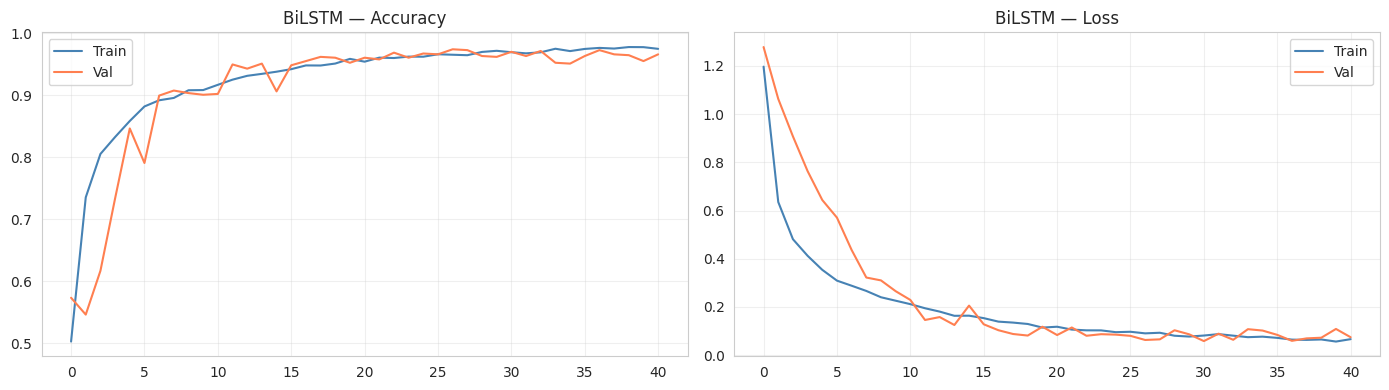


══════════════════════════════════════════════════
  📊 BiLSTM
══════════════════════════════════════════════════
  Accuracy          : 0.9226 (92.26%)
  Balanced Accuracy : 0.9207
  Macro F1          : 0.9225
  MCC               : 0.9077
                    precision    recall  f1-score   support

            LAYING       0.89      0.98      0.93       496
           SITTING       0.91      0.88      0.90       471
          STANDING       0.98      0.90      0.94       420
           WALKING       0.95      0.85      0.89       491
WALKING_DOWNSTAIRS       0.84      0.96      0.90       532
  WALKING_UPSTAIRS       1.00      0.96      0.98       537

          accuracy                           0.92      2947
         macro avg       0.93      0.92      0.92      2947
      weighted avg       0.93      0.92      0.92      2947



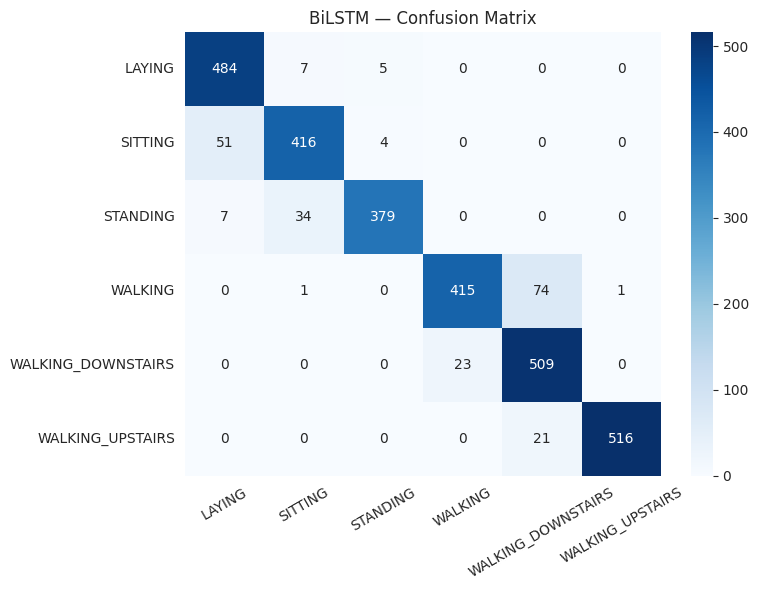

{'Modèle': 'BiLSTM', 'Accuracy': 0.9226, 'Balanced_Accuracy': np.float64(0.9207), 'Macro_F1': 0.9225, 'MCC': np.float64(0.9077)}


In [27]:
# ── Labels ───────────────────────────────────────────────
subject_train = pd.read_csv(f'{BASE}/train/subject_train.txt', header=None)[0]
subject_test  = pd.read_csv(f'{BASE}/test/subject_test.txt',   header=None)[0]
y_train_raw   = pd.read_csv(f'{BASE}/train/y_train.txt',       header=None)[0]
y_test_raw    = pd.read_csv(f'{BASE}/test/y_test.txt',         header=None)[0]

label_map   = {1:'WALKING', 2:'WALKING_UPSTAIRS', 3:'WALKING_DOWNSTAIRS',
               4:'SITTING', 5:'STANDING', 6:'LAYING'}
CLASS_NAMES = ['LAYING','SITTING','STANDING','WALKING',
               'WALKING_DOWNSTAIRS','WALKING_UPSTAIRS']

le          = LabelEncoder()
y_train     = le.fit_transform(y_train_raw)
y_test      = le.transform(y_test_raw)
NUM_CLASSES = len(le.classes_)
y_train_ohe = to_categorical(y_train, NUM_CLASSES)
y_test_ohe  = to_categorical(y_test,  NUM_CLASSES)

print(f'✅ NUM_CLASSES : {NUM_CLASSES}')
print(f'✅ y_train     : {y_train.shape}')

# ── BiLSTM ───────────────────────────────────────────────
def build_bilstm_fast(input_shape, num_classes):
    inputs = keras.Input(shape=input_shape)

    x = layers.Bidirectional(
        layers.LSTM(64, return_sequences=True, dropout=0.2)
    )(inputs)
    x = layers.BatchNormalization()(x)

    x = layers.Bidirectional(
        layers.LSTM(32, return_sequences=False, dropout=0.2)
    )(x)
    x = layers.BatchNormalization()(x)

    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = Model(inputs, outputs, name='BiLSTM_Fast')
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

bilstm = build_bilstm_fast(X_train_3d.shape[1:], NUM_CLASSES)
bilstm.summary()
print(f'Paramètres : {bilstm.count_params():,}')

# ── Entraînement ─────────────────────────────────────────
history_lstm = bilstm.fit(
    X_train_3d, y_train_ohe,
    epochs=100,
    batch_size=256,
    validation_split=0.1,
    callbacks=get_callbacks('BiLSTM'),
    verbose=1
)

# ── Epochs exact ─────────────────────────────────────────
best_epoch   = np.argmax(history_lstm.history['val_accuracy']) + 1
total_epochs = len(history_lstm.history['val_accuracy'])
best_val_acc = max(history_lstm.history['val_accuracy'])

print(f'\n{"═"*45}')
print(f'  ⏱️  Epochs total      : {total_epochs}')
print(f'  🏆  Meilleure epoch   : {best_epoch}')
print(f'  📈  Meilleure val_acc : {best_val_acc:.4f}')
print(f'{"═"*45}')

# ── Visualisation & Évaluation ───────────────────────────
plot_history(history_lstm, 'BiLSTM')
res = evaluate_model(bilstm, X_test_3d, y_test, 'BiLSTM')
results.append(res)
print(res)

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import math
import os
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, classification_report,
                              confusion_matrix, balanced_accuracy_score,
                              f1_score, matthews_corrcoef)

os.makedirs('models', exist_ok=True)

print('TensorFlow :', tf.__version__)
print('GPU        :', tf.config.list_physical_devices('GPU'))
print('✅ Imports OK')

TensorFlow : 2.20.0
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✅ Imports OK


In [29]:
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/UCI HAR Dataset'

# ── Features avec noms uniques ───────────────────────────
with open(f'{BASE}/features.txt') as f:
    features_raw = [line.strip().split(' ', 1)[1] for line in f.readlines()]

seen = {}
features_unique = []
for feat in features_raw:
    if feat in seen:
        seen[feat] += 1
        features_unique.append(f'{feat}_{seen[feat]}')
    else:
        seen[feat] = 0
        features_unique.append(feat)

print(f'Features uniques : {len(features_unique)}')

# ── Charger X ────────────────────────────────────────────
X_train_raw = pd.read_csv(f'{BASE}/train/X_train.txt',
                           sep=r'\s+', engine='python',
                           header=None, names=features_unique)
X_test_raw  = pd.read_csv(f'{BASE}/test/X_test.txt',
                           sep=r'\s+', engine='python',
                           header=None, names=features_unique)

# ── Charger y ────────────────────────────────────────────
y_train_raw = pd.read_csv(f'{BASE}/train/y_train.txt', header=None)[0]
y_test_raw  = pd.read_csv(f'{BASE}/test/y_test.txt',   header=None)[0]

print(f'X_train_raw : {X_train_raw.shape}')
print(f'X_test_raw  : {X_test_raw.shape}')
print('✅ Données chargées')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Features uniques : 561
X_train_raw : (7352, 561)
X_test_raw  : (2947, 561)
✅ Données chargées


In [30]:
CLASS_NAMES = ['LAYING','SITTING','STANDING','WALKING',
               'WALKING_DOWNSTAIRS','WALKING_UPSTAIRS']

# ── Encodage labels ──────────────────────────────────────
le          = LabelEncoder()
y_train     = le.fit_transform(y_train_raw)
y_test      = le.transform(y_test_raw)
NUM_CLASSES = len(le.classes_)
y_train_ohe = to_categorical(y_train, NUM_CLASSES)
y_test_ohe  = to_categorical(y_test,  NUM_CLASSES)

# ── Normalisation ────────────────────────────────────────
scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train_raw.values)
X_test  = scaler.transform(X_test_raw.values)

# ── Reshape (7352, 33, 17) — 33×17 = 561 ────────────────
X_train_3d = X_train.reshape(X_train.shape[0], 33, 17)
X_test_3d  = X_test.reshape(X_test.shape[0],   33, 17)

print(f'X_train_3d  : {X_train_3d.shape}')
print(f'X_test_3d   : {X_test_3d.shape}')
print(f'NUM_CLASSES : {NUM_CLASSES}')
print(f'Classes     : {CLASS_NAMES}')
print('✅ Préprocessing OK')

X_train_3d  : (7352, 33, 17)
X_test_3d   : (2947, 33, 17)
NUM_CLASSES : 6
Classes     : ['LAYING', 'SITTING', 'STANDING', 'WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']
✅ Préprocessing OK


In [31]:
def augment_time_series(X, y, factor=0.5, seed=42):
    """
    Augmentation de séries temporelles :
    - Jittering  : ajout de bruit gaussien
    - Scaling    : changement d'amplitude
    - Time Warp  : décalage temporel
    """
    np.random.seed(seed)
    n   = int(len(X) * factor)
    idx = np.random.choice(len(X), n, replace=False)
    X_aug, y_aug = [], []

    for i in idx:
        choice = np.random.randint(3)

        if choice == 0:   # Jittering
            noise = np.random.normal(0, 0.05, X[i].shape)
            X_aug.append(X[i] + noise)

        elif choice == 1:   # Scaling
            scale = np.random.uniform(0.8, 1.2)
            X_aug.append(X[i] * scale)

        else:   # Time Warping
            shift = np.random.randint(-3, 3)
            X_aug.append(np.roll(X[i], shift, axis=0))

        y_aug.append(y[i])

    X_combined = np.concatenate([X, np.array(X_aug)], axis=0)
    y_combined = np.concatenate([y, np.array(y_aug)], axis=0)

    # Shuffle
    idx_shuffle = np.random.permutation(len(X_combined))
    return X_combined[idx_shuffle], y_combined[idx_shuffle]

X_train_aug, y_train_aug = augment_time_series(X_train_3d, y_train_ohe, factor=0.5)

print(f'Train original  : {X_train_3d.shape}')
print(f'Train augmenté  : {X_train_aug.shape}  (+50% samples)')
print('✅ Augmentation OK')

Train original  : (7352, 33, 17)
Train augmenté  : (11028, 33, 17)  (+50% samples)
✅ Augmentation OK


In [32]:
# ── Focal Loss ───────────────────────────────────────────
def focal_loss(gamma=2.0, alpha=0.25):
    def loss(y_true, y_pred):
        y_pred  = tf.clip_by_value(y_pred, 1e-7, 1.0)
        ce      = -y_true * tf.math.log(y_pred)
        weight  = alpha * y_true * tf.pow(1 - y_pred, gamma)
        return tf.reduce_mean(tf.reduce_sum(weight * ce, axis=1))
    return loss

# ── Cosine Annealing LR ──────────────────────────────────
def cosine_lr(epoch, lr, total_epochs=100, min_lr=1e-5, max_lr=1e-3):
    return min_lr + 0.5*(max_lr - min_lr)*(1 + math.cos(math.pi * epoch / total_epochs))

# ── Callbacks ────────────────────────────────────────────
def get_callbacks_improved(model_name, patience=15):
    return [
        EarlyStopping(
            monitor='val_accuracy', patience=patience,
            restore_best_weights=True, verbose=1
        ),
        keras.callbacks.LearningRateScheduler(
            lambda epoch, lr: cosine_lr(epoch, lr), verbose=0
        )
    ]

print('✅ Focal Loss + Cosine LR définis')

✅ Focal Loss + Cosine LR définis


In [33]:
def plot_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    fig.suptitle(f'{model_name} — Courbes entraînement',
                 fontsize=13, fontweight='bold')

    axes[0].plot(history.history['accuracy'],     label='Train', color='steelblue')
    axes[0].plot(history.history['val_accuracy'], label='Val',   color='coral')
    axes[0].set_title('Accuracy'); axes[0].set_xlabel('Epoch')
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(history.history['loss'],     label='Train', color='steelblue')
    axes[1].plot(history.history['val_loss'], label='Val',   color='coral')
    axes[1].set_title('Loss'); axes[1].set_xlabel('Epoch')
    axes[1].legend(); axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'models/{model_name}_curves.png', dpi=150, bbox_inches='tight')
    plt.show()

def evaluate_model(model, X_input, y_int, model_name):
    y_pred   = np.argmax(model.predict(X_input, verbose=0), axis=1)
    acc      = accuracy_score(y_int, y_pred)
    bal_acc  = balanced_accuracy_score(y_int, y_pred)
    macro_f1 = f1_score(y_int, y_pred, average='macro')
    mcc      = matthews_corrcoef(y_int, y_pred)

    print(f'\n{"═"*55}')
    print(f'  📊 {model_name}')
    print(f'{"═"*55}')
    print(f'  Accuracy          : {acc:.4f} ({acc*100:.2f}%)')
    print(f'  Balanced Accuracy : {bal_acc:.4f}')
    print(f'  Macro F1          : {macro_f1:.4f}')
    print(f'  MCC               : {mcc:.4f}')
    print(f'{"═"*55}')
    print(classification_report(y_int, y_pred, target_names=CLASS_NAMES))

    cm = confusion_matrix(y_int, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(f'{model_name} — Confusion Matrix',
              fontsize=13, fontweight='bold')
    plt.ylabel('Réel'); plt.xlabel('Prédit')
    plt.xticks(rotation=30); plt.tight_layout()
    plt.savefig(f'models/{model_name}_confusion.png',
                dpi=150, bbox_inches='tight')
    plt.show()

    return {
        'Modèle'           : model_name,
        'Accuracy'         : round(acc, 4),
        'Balanced_Accuracy': round(bal_acc, 4),
        'Macro_F1'         : round(macro_f1, 4),
        'MCC'              : round(mcc, 4)
    }

results = []
print('✅ Fonctions prêtes')

✅ Fonctions prêtes


In [34]:
def build_bilstm_improved(input_shape, num_classes):
    inputs = keras.Input(shape=input_shape)

    # ── BiLSTM 1 ─────────────────────────────────────────
    x = layers.Bidirectional(
        layers.LSTM(128, return_sequences=True, dropout=0.2),
        name='bilstm_1'
    )(inputs)
    x = layers.BatchNormalization()(x)

    # ── BiLSTM 2 ─────────────────────────────────────────
    x = layers.Bidirectional(
        layers.LSTM(64, return_sequences=True, dropout=0.2),
        name='bilstm_2'
    )(x)
    x = layers.BatchNormalization()(x)

    # ── Multi-Head Attention ─────────────────────────────
    attn = layers.MultiHeadAttention(
        num_heads=4, key_dim=16, name='attention'
    )(x, x)
    x = layers.Add()([x, attn])          # Residual connection
    x = layers.LayerNormalization()(x)

    # ── Global Pooling ───────────────────────────────────
    x = layers.GlobalAveragePooling1D()(x)

    # ── Classifieur ──────────────────────────────────────
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = Model(inputs, outputs, name='BiLSTM_Attention')
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss=focal_loss(gamma=2.0),      # ← Focal Loss
        metrics=['accuracy']
    )
    return model

bilstm_v2 = build_bilstm_improved(X_train_3d.shape[1:], NUM_CLASSES)
bilstm_v2.summary()
print(f'\nTotal paramètres : {bilstm_v2.count_params():,}')

Model: "BiLSTM_Attention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 33, 17)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm_1            │ (None, 33, 256)   │    149,504 │ input_layer_1[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 33, 256)   │      1,024 │ bilstm_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm_2            │ (None, 33, 128)   │    164,352 │ batch_normalizat… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 33, 128)   │        512 │ bilstm_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ (None, 33, 128)   │     33,088 │ batch_normalizat… │
│ (MultiHeadAttentio… │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 33, 128)   │          0 │ batch_normalizat… │
│                     │                   │            │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 33, 128)   │        256 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 128)       │     16,512 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 128)       │          0 │ dense_4[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 64)        │      8,256 │ dropout_11[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, 64)        │          0 │ dense_5[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 6)         │        390 │ dropout_12[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 373,894 (1.43 MB)

 Trainable params: 373,126 (1.42 MB)

 Non-trainable params: 768 (3.00 KB)


Total paramètres : 373,894


Epoch 1/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 11s 41ms/step - accuracy: 0.5764 - loss: 0.1205 - val_accuracy: 0.6278 - val_loss: 0.1374 - learning_rate: 0.0010
Epoch 2/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.7589 - loss: 0.0508 - val_accuracy: 0.7794 - val_loss: 0.0580 - learning_rate: 9.9976e-04
Epoch 3/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.8153 - loss: 0.0361 - val_accuracy: 0.8446 - val_loss: 0.0422 - learning_rate: 9.9902e-04
Epoch 4/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.8566 - loss: 0.0275 - val_accuracy: 0.8303 - val_loss: 0.0411 - learning_rate: 9.9780e-04
Epoch 5/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.8842 - loss: 0.0212 - val_accuracy: 0.8711 - val_loss: 0.0370 - learning_rate: 9.9610e-04
Epoch 6/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.8976 - loss: 0.0192 - val_accuracy: 0.8894 - val_loss: 0.0351 - learning_rate: 9.9391e-04
Epoch 7/100
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.9

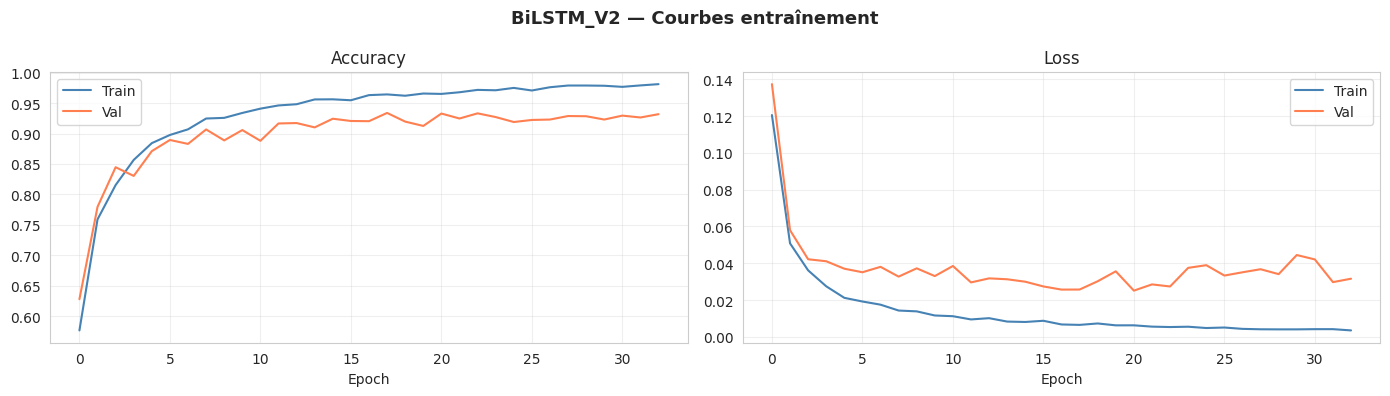


═══════════════════════════════════════════════════════
  📊 BiLSTM_V2
═══════════════════════════════════════════════════════
  Accuracy          : 0.9338 (93.38%)
  Balanced Accuracy : 0.9331
  Macro F1          : 0.9343
  MCC               : 0.9207
═══════════════════════════════════════════════════════
                    precision    recall  f1-score   support

            LAYING       0.93      0.96      0.94       496
           SITTING       0.91      0.94      0.92       471
          STANDING       0.98      0.92      0.95       420
           WALKING       0.93      0.89      0.91       491
WALKING_DOWNSTAIRS       0.87      0.94      0.90       532
  WALKING_UPSTAIRS       1.00      0.96      0.98       537

          accuracy                           0.93      2947
         macro avg       0.94      0.93      0.93      2947
      weighted avg       0.94      0.93      0.93      2947



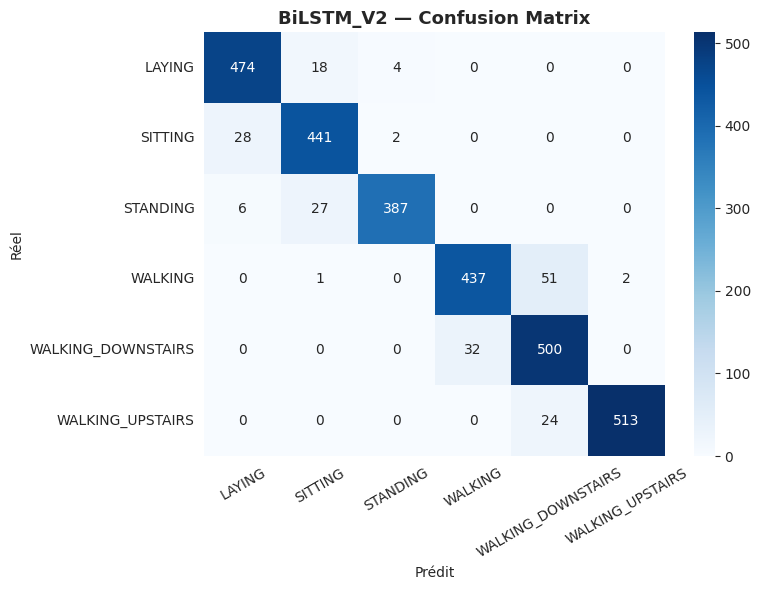

{'Modèle': 'BiLSTM_V2', 'Accuracy': 0.9338, 'Balanced_Accuracy': np.float64(0.9331), 'Macro_F1': 0.9343, 'MCC': np.float64(0.9207)}


In [35]:
# ── Entraînement ─────────────────────────────────────────
history_v2 = bilstm_v2.fit(
    X_train_aug, y_train_aug,          # ← données augmentées
    epochs=100,
    batch_size=128,
    validation_data=(X_test_3d, y_test_ohe),
    callbacks=get_callbacks_improved('BiLSTM_V2'),
    verbose=1
)

# ── Epochs exact ─────────────────────────────────────────
best_epoch   = np.argmax(history_v2.history['val_accuracy']) + 1
total_epochs = len(history_v2.history['val_accuracy'])
best_val_acc = max(history_v2.history['val_accuracy'])

print(f'\n{"═"*45}')
print(f'  ⏱️  Epochs total      : {total_epochs}')
print(f'  🏆  Meilleure epoch   : {best_epoch}')
print(f'  📈  Meilleure val_acc : {best_val_acc:.4f}')
print(f'{"═"*45}')
# ── Visualisation & Évaluation ───────────────────────────
plot_history(history_v2, 'BiLSTM_V2')
res_v2 = evaluate_model(bilstm_v2, X_test_3d, y_test, 'BiLSTM_V2')
results.append(res_v2)
print(res_v2)

In [36]:
# ── Architecture ─────────────────────────────────────────────────
def build_cnn_lstm(input_shape, num_classes):
    inputs = keras.Input(shape=input_shape, name='input')

    # ── Partie CNN (extraction de features locales) ──────────────
    x = layers.Conv1D(64,  kernel_size=5, padding='same',
                      activation='relu', name='conv1')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(pool_size=2)(x)

    x = layers.Conv1D(128, kernel_size=3, padding='same',
                      activation='relu', name='conv2')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(pool_size=2)(x)
    x = layers.Dropout(0.3)(x)

    # ── Partie LSTM (dépendances temporelles longues) ────────────
    x = layers.LSTM(128, return_sequences=True,
                    dropout=0.3, name='lstm_1')(x)
    x = layers.LSTM(64,  return_sequences=False,
                    dropout=0.3, name='lstm_2')(x)
    x = layers.BatchNormalization()(x)

    # ── Classifieur ──────────────────────────────────────────────
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation='softmax', name='output')(x)

    model = Model(inputs, outputs, name='CNN_LSTM')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

cnn_lstm = build_cnn_lstm(X_train_3d.shape[1:], NUM_CLASSES)
cnn_lstm.summary()
print(f'\nTotal paramètres : {cnn_lstm.count_params():,}')

Model: "CNN_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 33, 17)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv1D)                  │ (None, 33, 64)         │         5,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 33, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 16, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv1D)                  │ (None, 16, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 16, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 8, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 8, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 8, 128)         │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 216,774 (846.77 KB)

 Trainable params: 216,262 (844.77 KB)

 Non-trainable params: 512 (2.00 KB)


Total paramètres : 216,774


Epoch 1/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4853 - loss: 1.2567

104/104 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - accuracy: 0.6217 - loss: 0.8967 - val_accuracy: 0.8043 - val_loss: 0.6918 - learning_rate: 0.0010
Epoch 2/100
101/104 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8195 - loss: 0.4262

104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.8427 - loss: 0.3865 - val_accuracy: 0.9226 - val_loss: 0.2463 - learning_rate: 0.0010
Epoch 3/100
100/104 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9015 - loss: 0.2665

104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9083 - loss: 0.2449 - val_accuracy: 0.9701 - val_loss: 0.0852 - learning_rate: 0.0010
Epoch 4/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9330 - loss: 0.1802 - val_accuracy: 0.9674 - val_loss: 0.0977 - learning_rate: 0.0010
Epoch 5/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9530 - loss: 0.1420 - val_accuracy: 0.9647 - val_loss: 0.0791 - learning_rate: 0.0010
Epoch 6/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9606 - loss: 0.1200 - val_accuracy: 0.9633 - val_loss: 0.0826 - learning_rate: 0.0010
Epoch 7/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9622 - loss: 0.1109 - val_accuracy: 0.9647 - val_loss: 0.0786 - learning_rate: 0.0010
Epoch 8/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9670 - loss: 0.0999 - val_accuracy: 0.9524 - val_loss: 0.1341 - learning_rate: 0.0010
Epoch 9/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9726 - loss: 0.0835 

104/104 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9794 - loss: 0.0626 - val_accuracy: 0.9742 - val_loss: 0.0978 - learning_rate: 0.0010
Epoch 13/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9837 - loss: 0.0622 - val_accuracy: 0.9674 - val_loss: 0.1008 - learning_rate: 5.0000e-04
Epoch 14/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9869 - loss: 0.0378 - val_accuracy: 0.9620 - val_loss: 0.1915 - learning_rate: 5.0000e-04
Epoch 15/100
100/104 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9883 - loss: 0.0378

104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9893 - loss: 0.0339 - val_accuracy: 0.9769 - val_loss: 0.0850 - learning_rate: 5.0000e-04
Epoch 16/100
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9885 - loss: 0.0333 - val_accuracy: 0.9633 - val_loss: 0.1037 - learning_rate: 5.0000e-04
Epoch 17/100
101/104 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9882 - loss: 0.0322
Epoch 17: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9890 - loss: 0.0327 - val_accuracy: 0.9416 - val_loss: 0.3306 - learning_rate: 5.0000e-04
Epoch 17: early stopping
Restoring model weights from the end of the best epoch: 7.


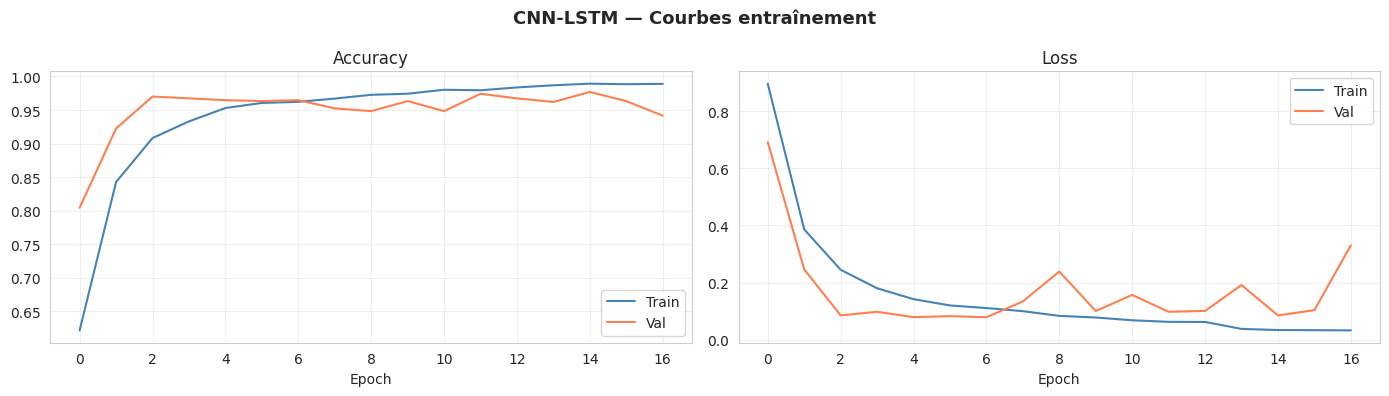


═══════════════════════════════════════════════════════
  📊 CNN-LSTM
═══════════════════════════════════════════════════════
  Accuracy          : 0.9097 (90.97%)
  Balanced Accuracy : 0.9057
  Macro F1          : 0.9074
  MCC               : 0.8921
═══════════════════════════════════════════════════════
                    precision    recall  f1-score   support

            LAYING       0.89      0.97      0.92       496
           SITTING       0.85      0.91      0.88       471
          STANDING       0.97      0.79      0.87       420
           WALKING       0.91      0.87      0.89       491
WALKING_DOWNSTAIRS       0.87      0.93      0.90       532
  WALKING_UPSTAIRS       0.99      0.97      0.98       537

          accuracy                           0.91      2947
         macro avg       0.91      0.91      0.91      2947
      weighted avg       0.91      0.91      0.91      2947



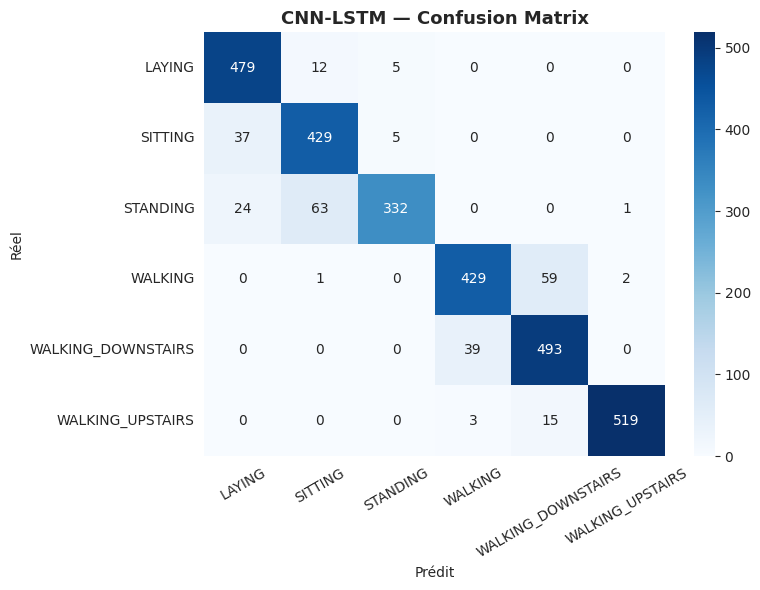

In [37]:
# ── Entraînement ─────────────────────────────────────────────────
history_cnn_lstm = cnn_lstm.fit(
    X_train_3d, y_train_ohe,
    epochs=100,
    batch_size=64,
    validation_split=0.1,
    callbacks=get_callbacks('CNN_LSTM'),
    verbose=1
)

# ── Visualisation & Évaluation ───────────────────────────────────
plot_history(history_cnn_lstm, 'CNN-LSTM')
res = evaluate_model(cnn_lstm, X_test_3d, y_test, 'CNN-LSTM')
results.append(res)